In [31]:
# IMPORTS

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn import metrics
from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix
from sklearn.metrics import accuracy_score
from sklearn.metrics import roc_auc_score

In [32]:
# Combining the datasets together with a new column for run_id and road_id

dfA1 = pd.read_csv("../dataset/cleaned/Iisingintie0.csv")
dfA2 = pd.read_csv("../dataset/cleaned/Iisingintie1.csv")
dfA3 = pd.read_csv("../dataset/cleaned/Iisingintie2.csv")

dfB1 = pd.read_csv("../dataset/cleaned/Sinetänsalmentie0.csv")
dfB2 = pd.read_csv("../dataset/cleaned/Sinetänsalmentie1.csv")
dfB3 = pd.read_csv("../dataset/cleaned/Sinetänsalmentie2.csv")
dfB4 = pd.read_csv("../dataset/cleaned/Sinetänsalmentie3.csv")

dfC1 = pd.read_csv("../dataset/cleaned/Kaittiaisentie0.csv")


runs = {
    "A1": (dfA1, "A"), "A2": (dfA2, "A"), "A3": (dfA3, "A"),
    "B1": (dfB1, "B"), "B2": (dfB2, "B"), "B3": (dfB3, "B"), "B4": (dfB4, "B"),
    "C1": (dfC1, "C"),
}

df = pd.concat(
    [d.assign(run_id=rid, road_id=road) for rid, (d, road) in runs.items()],
    ignore_index=True,
)

df["AccZ_max"] = df["AccZ"].max()

df["AccMagnitude"] = np.sqrt(
    df["AccX"]**2 +
    df["AccY"]**2 +
    df["AccZ"]**2
)

df["GyrMagnitude"] = np.sqrt(
    df["GyrX"]**2 +
    df["GyrY"]**2 +
    df["GyrZ"]**2
)

In [33]:
df

,Timer(ms),Loc(m),CElev(m),Roll(deg),Pitch(deg),Yaw(deg),AccX,AccY,AccZ,GyrX,GyrY,GyrZ,RBCSV_80(cf),Speed_kmh,Frostbumps,run_id,road_id,AccZ_max,AccMagnitude,GyrMagnitude
0,45493158.5,3850.503,106.794,1.1747,-3.0780,141.0204,1.53481,0.05712,9.58495,0.03196,0.00072,-0.00300,0.16845,62.1936,0,A1,A,24.57569,9.707223,0.032109
1,45493161.0,3850.546,106.794,1.2245,-3.0428,141.1350,1.51066,-0.04196,10.50449,0.02201,0.00598,-0.01390,0.16846,62.2044,0,A1,A,24.57569,10.612642,0.026710
2,45493163.5,3850.589,106.794,1.2281,-3.0428,141.1349,1.15831,0.37071,10.76888,0.01993,0.00065,-0.00562,0.16846,62.2116,0,A1,A,24.57569,10.837338,0.020717
3,45493166.0,3850.633,106.794,1.2330,-3.0430,141.1341,1.03301,0.31102,11.42271,0.02887,-0.00077,-0.01012,0.16845,62.2224,0,A1,A,24.57569,11.473541,0.030602
4,45493168.5,3850.676,106.794,1.2363,-3.0431,141.1329,0.99574,-0.37334,11.76243,0.01783,0.00007,-0.01306,0.16843,62.2332,0,A1,A,24.57569,11.810404,0.022102
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
396931,48391434.5,3157.848,120.738,0.6624,-3.4168,-47.3993,-0.40183,0.28938,9.78850,-0.02246,0.01337,-0.00194,0.42374,32.9796,0,C1,C,24.57569,9.801017,0.026210
396932,48391437.0,3157.871,120.738,0.6598,-3.4154,-47.3987,-0.42412,0.19784,9.78453,-0.02360,0.01054,-0.00004,0.42612,32.9760,0,C1,C,24.57569,9.795716,0.025847
396933,48391439.5,3157.894,120.739,0.6575,-3.4144,-47.3981,-0.38394,0.20489,9.77121,-0.02072,0.00785,-0.00054,0.42740,32.9724,0,C1,C,24.57569,9.780896,0.022164
396934,48391442.0,3157.917,120.739,0.6554,-3.4136,-47.3982,-0.32756,0.11798,9.63872,-0.02030,0.00637,-0.00511,0.42867,32.9652,0,C1,C,24.57569,9.645006,0.021881


In [34]:
run_names = list(runs.keys())
print(run_names)

['A1', 'A2', 'A3', 'B1', 'B2', 'B3', 'B4', 'C1']


In [35]:
df

,Timer(ms),Loc(m),CElev(m),Roll(deg),Pitch(deg),Yaw(deg),AccX,AccY,AccZ,GyrX,GyrY,GyrZ,RBCSV_80(cf),Speed_kmh,Frostbumps,run_id,road_id,AccZ_max,AccMagnitude,GyrMagnitude
0,45493158.5,3850.503,106.794,1.1747,-3.0780,141.0204,1.53481,0.05712,9.58495,0.03196,0.00072,-0.00300,0.16845,62.1936,0,A1,A,24.57569,9.707223,0.032109
1,45493161.0,3850.546,106.794,1.2245,-3.0428,141.1350,1.51066,-0.04196,10.50449,0.02201,0.00598,-0.01390,0.16846,62.2044,0,A1,A,24.57569,10.612642,0.026710
2,45493163.5,3850.589,106.794,1.2281,-3.0428,141.1349,1.15831,0.37071,10.76888,0.01993,0.00065,-0.00562,0.16846,62.2116,0,A1,A,24.57569,10.837338,0.020717
3,45493166.0,3850.633,106.794,1.2330,-3.0430,141.1341,1.03301,0.31102,11.42271,0.02887,-0.00077,-0.01012,0.16845,62.2224,0,A1,A,24.57569,11.473541,0.030602
4,45493168.5,3850.676,106.794,1.2363,-3.0431,141.1329,0.99574,-0.37334,11.76243,0.01783,0.00007,-0.01306,0.16843,62.2332,0,A1,A,24.57569,11.810404,0.022102
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
396931,48391434.5,3157.848,120.738,0.6624,-3.4168,-47.3993,-0.40183,0.28938,9.78850,-0.02246,0.01337,-0.00194,0.42374,32.9796,0,C1,C,24.57569,9.801017,0.026210
396932,48391437.0,3157.871,120.738,0.6598,-3.4154,-47.3987,-0.42412,0.19784,9.78453,-0.02360,0.01054,-0.00004,0.42612,32.9760,0,C1,C,24.57569,9.795716,0.025847
396933,48391439.5,3157.894,120.739,0.6575,-3.4144,-47.3981,-0.38394,0.20489,9.77121,-0.02072,0.00785,-0.00054,0.42740,32.9724,0,C1,C,24.57569,9.780896,0.022164
396934,48391442.0,3157.917,120.739,0.6554,-3.4136,-47.3982,-0.32756,0.11798,9.63872,-0.02030,0.00637,-0.00511,0.42867,32.9652,0,C1,C,24.57569,9.645006,0.021881


In [36]:
feature_cols = ["AccX", "AccY", "AccZ", "GyrX", "GyrY", "GyrZ",
                "Pitch(deg)", "Roll(deg)", "Speed_kmh", "RBCSV_80(cf)", "AccMagnitude", "GyrMagnitude", "AccZ_max"]


In [37]:
def make_row_windows(run_df, win=0, stride=0, min_percentage=0.1):
    run_df = run_df.sort_values("Timer(ms)")

    X = run_df[feature_cols].to_numpy(np.float32)
    y = run_df["Frostbumps"].to_numpy()

    X_clips, y_clips = [], []

    for start in range(0, len(X) - win + 1, stride):
        end = start + win

        X_clips.append(X[start:end])

        bump_percentage = y[start:end].mean()
        y_clips.append(int(bump_percentage >= min_percentage))

    return np.array(X_clips), np.array(y_clips)

In [38]:
def get_clips(run_names):
    all_X, all_y = [], []
    for name in run_names:
        one_run = df[df["run_id"] == name]
        X, y = make_row_windows(one_run, win=100, stride=80)
        all_X.append(X)
        all_y.append(y)
    return np.concatenate(all_X), np.concatenate(all_y)

In [39]:
# Checking the number of windows per run

for run in ["A1", "A2", "A3", "B1", "B2", "B3", "B4"]:
    X, y = get_clips([run])

    print(
        f"{run}: {len(y)} windows, "
        f"{y.mean():.1%} positive"
    )

A1: 710 windows, 22.1% positive
A2: 943 windows, 21.1% positive
A3: 1433 windows, 19.2% positive
B1: 80 windows, 58.8% positive
B2: 95 windows, 44.2% positive
B3: 115 windows, 47.0% positive
B4: 226 windows, 35.0% positive


In [40]:
# Training, validation, test splits

Xtr, ytr = get_clips(["A3","B3","B4","B1"])
Xva, yva = get_clips(["A1"])
Xte, yte = get_clips(["A2","B2"])

print(Xtr.shape, Xva.shape, Xte.shape)
print(ytr.mean(), yva.mean(), yte.mean())

(1854, 100, 13) (710, 100, 13) (1038, 100, 13)
0.24541531823085222 0.2211267605633803 0.2321772639691715


In [41]:
from sklearn.preprocessing import StandardScaler, MinMaxScaler

n_features = Xtr.shape[-1]      # 9 now

scaler = StandardScaler()
scaler.fit(Xtr.reshape(-1, n_features))

Xtr = scaler.transform(Xtr.reshape(-1, n_features)).reshape(Xtr.shape)
Xva = scaler.transform(Xva.reshape(-1, n_features)).reshape(Xva.shape)
Xte = scaler.transform(Xte.reshape(-1, n_features)).reshape(Xte.shape)

## NN stuff starts here


First I'm trying to use a Keras tuner to optimize my model layers.

In [42]:



# import keras_tuner
# from tensorflow import keras
# from tensorflow.keras import layers

# def build_model(hp):
#     norm = layers.Normalization(axis=-1)
#     norm.adapt(Xtr)

#     f1 = hp.Choice("filters1", [8, 16, 32])
#     f2 = hp.Choice("filters2", [8, 16, 32])
#     k1 = hp.Choice("kernel1", [5, 9, 15])
#     k2 = hp.Choice("kernel2", [3, 5, 9])
#     l2 = hp.Choice("l2", [0.0, 1e-4, 1e-3, 1e-2])
#     drop = hp.Float("dropout", 0.2, 0.6, step=0.1)
#     lr = hp.Choice("lr", [1e-4, 3e-4, 1e-3])
#     use_dense = hp.Boolean("hidden_dense")

#     reg = keras.regularizers.l2(l2) if l2 > 0 else None

#     m = [layers.Input(shape=Xtr.shape[1:]), norm,
#          layers.Conv1D(f1, k1, padding="same", activation="relu", kernel_regularizer=reg),
#          layers.MaxPooling1D(2),
#          layers.Conv1D(f2, k2, padding="same", activation="relu", kernel_regularizer=reg),
#          layers.GlobalMaxPooling1D(),
#          layers.Dropout(drop)]
#     if use_dense:
#         m.append(layers.Dense(16, activation="relu", kernel_regularizer=reg))
#     m.append(layers.Dense(1, activation="sigmoid"))

#     model = keras.Sequential(m)
#     model.compile(optimizer=keras.optimizers.Adam(lr), loss="binary_crossentropy",
#                   metrics=[keras.metrics.AUC(curve="PR", name="pr_auc")])
#     return model


# import os

# tuner_path = os.path.expanduser("~/keras_tuner_results")
# os.makedirs(tuner_path, exist_ok=True)

# print(tuner_path)

# tuner = keras_tuner.Hyperband(
#     build_model,
#     objective=keras_tuner.Objective("val_pr_auc", direction="max"),
#     max_epochs=60,
#     factor=3,
#     seed=3,
#     directory=tuner_path,
#     project_name="frostbumps",
#     overwrite=True
# )

# tuner.search(
#     Xtr, ytr,
#     validation_data=(Xva, yva),
#     batch_size=32,
#     class_weight={0: 1.0, 1: 1.5640968184980821},
#     callbacks=[
#         keras.callbacks.EarlyStopping(
#             monitor="val_pr_auc",
#             mode="max",
#             patience=10,
#             restore_best_weights=True
#         )
#     ]
# )

In [43]:
# # 1. The best hyperparameters
# best_hp = tuner.get_best_hyperparameters(num_trials=1)[0]
# print(best_hp.values)          # dict: {'filters1': 16, 'kernel1': 9, ...}

# # 2. Overview of the top trials
# tuner.results_summary(num_trials=5)

# # 3. The best model (already trained, weights from the best epoch)
# best_model = tuner.get_best_models(num_models=1)[0]

In [44]:
# import optuna
# import numpy as np
# import keras
# from keras import layers
# from sklearn.metrics import average_precision_score


# def build_model():

#     model = keras.Sequential([
#         layers.Input(shape=Xtr.shape[1:]),
#         layers.Conv1D(16, 15, padding="same", activation="relu"),
#         layers.MaxPooling1D(2),
#         layers.Conv1D(32, 5, padding="same", activation="relu"),
#         layers.GlobalMaxPooling1D(),
#         layers.Dropout(0.4),
#         layers.Dense(1, activation="sigmoid")
#     ])

#     model.compile(
#         optimizer=keras.optimizers.Adam(1e-4),
#         loss="binary_crossentropy",
#         metrics=[keras.metrics.AUC(curve="PR", name="pr_auc")]
#     )

#     return model


# def objective(trial):
#     weight = trial.suggest_float("weight", 1, 10, log=True)

#     scores = []

#     for seed in [0, 1, 2]:
#         keras.utils.set_random_seed(seed)

#         model = build_model()

#         model.fit(
#             Xtr, ytr,
#             validation_data=(Xva, yva),
#             epochs=60,
#             batch_size=32,
#             verbose=0,
#             class_weight={0: 1, 1: weight},
#             callbacks=[
#                 keras.callbacks.EarlyStopping(
#                     monitor="val_pr_auc",
#                     mode="max",
#                     patience=15,
#                     restore_best_weights=True
#                 )
#             ]
#         )

#         predictions = model.predict(Xva, verbose=0).ravel()
#         scores.append(average_precision_score(yva, predictions))

#     return np.mean(scores)


# study = optuna.create_study(
#     direction="maximize",
#     sampler=optuna.samplers.TPESampler(seed=3)
# )

# study.optimize(objective, n_trials=20)

# print("Best class weight:", study.best_params["weight"])
# print("Best average precision:", study.best_value)



In [45]:
from tensorflow import keras
from tensorflow.keras import layers


weights = {0: 1, 1: 1}

seed=12553
keras.utils.set_random_seed(seed) 

model = keras.Sequential([
    layers.Input(shape=Xtr.shape[1:]),
    layers.LSTM(64),
    # layers.Conv1D(8, 15, padding="same", activation="relu"),
    # layers.MaxPooling1D(2),
    # layers.Conv1D(16, 5, padding="same", activation="relu"),
    # layers.GlobalMaxPooling1D(),
    layers.Dropout(0.3),
    layers.Dense(8, activation="relu"),
    layers.Dense(1, activation="sigmoid")
])

optimizer = keras.optimizers.Adam(learning_rate=0.0001)

model.compile(
    optimizer=optimizer,
    loss="binary_crossentropy",
    metrics=[
        keras.metrics.AUC(curve="PR", name="pr_auc")
    ]
)


history = model.fit(Xtr, ytr, validation_data=(Xva, yva),
          epochs=50, batch_size=32,
          class_weight=weights,
        #   callbacks=[keras.callbacks.EarlyStopping(
        #       monitor="val_loss", mode="max", patience=5, restore_best_weights=True)]
        )



Epoch 1/50
58/58 ━━━━━━━━━━━━━━━━━━━━ 2s 13ms/step - loss: 0.6449 - pr_auc: 0.2959 - val_loss: 0.7067 - val_pr_auc: 0.2733
Epoch 2/50
58/58 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - loss: 0.5950 - pr_auc: 0.3977 - val_loss: 0.7209 - val_pr_auc: 0.2951
Epoch 3/50
58/58 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - loss: 0.5322 - pr_auc: 0.4416 - val_loss: 0.7342 - val_pr_auc: 0.3099
Epoch 4/50
58/58 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - loss: 0.4733 - pr_auc: 0.5159 - val_loss: 0.7415 - val_pr_auc: 0.3272
Epoch 5/50
58/58 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - loss: 0.4632 - pr_auc: 0.5308 - val_loss: 0.7445 - val_pr_auc: 0.3553
Epoch 6/50
58/58 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - loss: 0.4544 - pr_auc: 0.5772 - val_loss: 0.7492 - val_pr_auc: 0.3873
Epoch 7/50
58/58 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - loss: 0.4492 - pr_auc: 0.5641 - val_loss: 0.7570 - val_pr_auc: 0.3987
Epoch 8/50
58/58 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - loss: 0.4438 - pr_auc: 0.5825 - val_loss: 0.7639 - val_pr_auc: 0.4235
Epoch 9/50
58/58

In [46]:
model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm_2 (LSTM)                   │ (None, 64)             │        19,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 8)              │           520 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 61,493 (240.21 KB)

 Trainable params: 20,497 (80.07 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 40,996 (160.14 KB)

In [47]:
from sklearn.metrics import precision_recall_curve
import numpy as np

y_val_prob = model.predict(Xva).ravel()

precision, recall, thresholds = precision_recall_curve(
    yva, y_val_prob
)

f1 = 2 * (precision[:-1] * recall[:-1]) / (
    precision[:-1] + recall[:-1] + 1e-8
)

best_idx = np.argmax(f1)

best_threshold = thresholds[best_idx]

print("Best threshold:", best_threshold)
print("Precision:", precision[best_idx])
print("Recall:", recall[best_idx])
print("F1:", f1[best_idx])

23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step
Best threshold: 0.8582616
Precision: 0.6379310344827587
Recall: 0.4713375796178344
F1: 0.542124537237317


<Axes: >

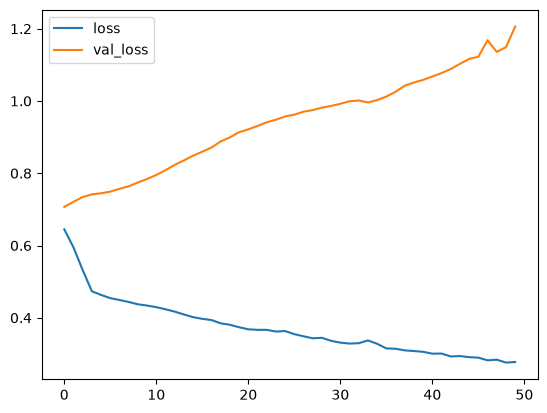

In [48]:
loss_df = pd.DataFrame(model.history.history)
loss_df[['loss', 'val_loss']].plot()

In [49]:
# compare the final model loss/accuracy/evaluation values
# the values should match mostly
print("Test data evaluation:")
print(model.evaluate(Xte, yte, verbose=0))
print("\nTrain data evaluation:")
print(model.evaluate(Xtr, ytr, verbose=0))

Test data evaluation:
[0.8053445219993591, 0.5594748854637146]

Train data evaluation:
[0.2679809033870697, 0.8365676403045654]


In [50]:

threshold = 0.5
y_pred_proba = model.predict(Xte).ravel()
test_predictions = (y_pred_proba >= threshold).astype(int)


33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step


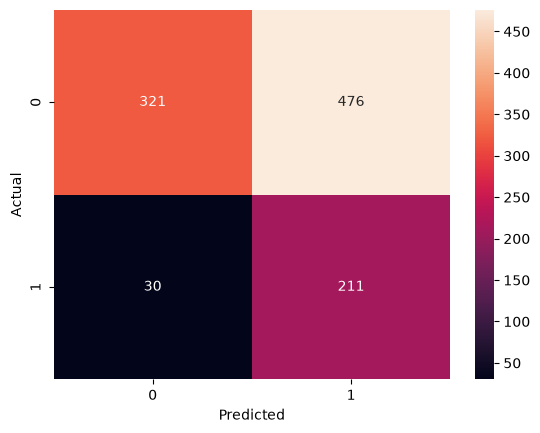

In [51]:


# confusion matrix
import seaborn as sns
sns.heatmap(confusion_matrix(yte, test_predictions), annot=True, fmt='g')

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()



In [52]:
from sklearn.metrics import confusion_matrix, classification_report
from sklearn.metrics import average_precision_score, roc_auc_score

# Get predicted probabilities
y_pred_proba = model.predict(Xte).ravel()

# Calculate AUC scores
pr_auc = average_precision_score(yte, y_pred_proba)
roc_auc = roc_auc_score(yte, y_pred_proba)

print(f"PR-AUC:  {pr_auc:.4f}")
print(f"ROC-AUC: {roc_auc:.4f}")
y_pred = (y_pred_proba >= threshold).astype(int)

print(confusion_matrix(yte, y_pred))
print(classification_report(yte, y_pred))

acc = accuracy_score(yte, test_predictions)
print("\nModel overall accuracy: {:.2f}%".format(acc * 100))

33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step
PR-AUC:  0.5602
ROC-AUC: 0.7553
[[321 476]
 [ 30 211]]
              precision    recall  f1-score   support

           0       0.91      0.40      0.56       797
           1       0.31      0.88      0.45       241

    accuracy                           0.51      1038
   macro avg       0.61      0.64      0.51      1038
weighted avg       0.77      0.51      0.53      1038


Model overall accuracy: 51.25%


In [53]:
y_prob = model.predict(Xte).ravel()

print(pd.Series(y_prob).describe())

33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step
count    1038.000000
mean        0.551588
std         0.297416
min         0.004321
25%         0.253875
50%         0.685235
75%         0.788661
max         0.925808
dtype: float64


In [54]:
y_prob = model.predict(Xte).ravel()

print("Actual frost bumps:", np.sum(yte == 1))
print("Predicted frost bumps:", np.sum(y_prob >= threshold))

print("\nProbabilities for actual frost bumps:")
print(y_prob[yte == 1])

33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step
Actual frost bumps: 241
Predicted frost bumps: 687

Probabilities for actual frost bumps:
[0.4735577  0.76430124 0.902795   0.8600114  0.82546246 0.8915236
 0.8610796  0.6705711  0.8567487  0.9212288  0.8145736  0.7567403
 0.835814   0.84860116 0.570906   0.75789    0.768962   0.8184254
 0.81379384 0.6781781  0.85080683 0.82605267 0.84995437 0.9154519
 0.8398007  0.7848475  0.82152736 0.83533657 0.69775724 0.4956088
 0.81505203 0.7398094  0.79439807 0.89557385 0.49506935 0.7329012
 0.78040874 0.8520052  0.82250583 0.7737408  0.7977519  0.79580426
 0.6571284  0.5038045  0.7182221  0.7114469  0.7427944  0.69847345
 0.85991746 0.86001235 0.77606577 0.7110804  0.75329256 0.82967776
 0.69943166 0.8832496  0.8601238  0.8080272  0.6663721  0.585395
 0.79234797 0.6181164  0.7750696  0.82058454 0.10549507 0.01557588
 0.05819954 0.05311066 0.0088412  0.39189732 0.8960749  0.58886147
 0.8633301  0.26466492 0.7605102  0.01137547 0.00854838 0.01027019
 0.01246